**Qué hicimos, en resumen**

```
(a) varias vistas del piso → una H por vista (como en el 4) → Zhang (ej. 3) → K
(b) 51 puntos del piso     → una H (como en el 4)          → con K sacamos R y t → reproyectamos
(c) cada captura           → píxel del piso → H⁻¹ (como en el 4) → metros → distancia / tiempo = velocidad
```

La pieza clave es la **homografía del piso**, la misma del ejercicio 4. La diferencia es que en el 4 nos alcanzaba con $H$ y su inversa, y acá además tenemos que **separarla** en $K$, $R$ y $\mathbf t$.


#### Preparar el entorno

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from alc import *      # módulo ALC del grupo (funciones del laboratorio y del TP)
from alc5 import *     # funciones del ejercicio 5: armarA_ej5, calcularMatrizK2D_ej5, estimar_focal, obtenerPose2D_ej5, pixel_a_metros, ...
np.set_printoptions(precision=3, suppress=True)

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

## Calculamos la homografía

Si el piso está en $Z=0$, un punto $(X,Y)$ se ve en el píxel $(u,v)$ así:
$$\lambda\begin{bmatrix}u\\v\\1\end{bmatrix}=H\begin{bmatrix}X\\Y\\1\end{bmatrix},\qquad H=K\,[\mathbf r_1\ \ \mathbf r_2\ \ \mathbf t]\quad(\text{salvo escala}).$$
La $H$ se estima, igual que en el ejercicio 4: armamos la matriz $Q$ de $2n\times9$ y tomamos el autovector de menor autovalor de $Q^TQ$, normalizando los puntos elegidos a mano. Usamos la misma función, `estimar_homografia_ej5`.

## a) Usamos el método de Zhang

Con una sola $H$ no alcanza: ahí están mezclados $K$ y la pose. Pero **todas las vistas comparten la misma $K$**, y eso nos da ecuaciones de más.

**La idea.** Sean $\mathbf c_i$ las columnas de $H$. Se cumple $\mathbf c_1=s\,K\mathbf r_1$ y $\mathbf c_2=s\,K\mathbf r_2$. Como $\mathbf r_1,\mathbf r_2$ son ortonormales, y llamando $B=K^{-T}K^{-1}$ (que es simétrica):
$$\mathbf c_1^TB\,\mathbf c_2=0,\qquad \mathbf c_1^TB\,\mathbf c_1-\mathbf c_2^TB\,\mathbf c_2=0 .$$
$B$ tiene 6 entradas distintas, $\mathbf b=(B_{11},B_{12},B_{22},B_{13},B_{23},B_{33})$, y cada producto es lineal en $\mathbf b$: $\mathbf c_i^TB\mathbf c_j=\mathbf v_{ij}^T\mathbf b$. 

Cada vista nos da 2 filas de una matriz $A\in\mathbb{R}^{2N\times6}$, y resolvemos $A\mathbf b=0$ igual que en el ejercicio 1b (autovector de menor autovalor de $A^TA$). Después hacemos Cholesky: $B=LL^T\Rightarrow K=(L^T)^{-1}$, y dividimos para que $K_{33}=1$.

 $K$ tiene 5 parámetros (4 si $\gamma=0$) y cada vista da 2 ecuaciones. Entonces $N\ge3$ vistas ($N\ge2$ si $\gamma=0$), y tienen que ser bien distintas entre sí.



In [ ]:
# Datos de las 4 vistas: 5 puntos con (X, Y, Z) en metros y su píxel (u_k, v_k) en cada vista k. El archivo va separado por ';'
df = pd.read_csv('recursos_entrega/salguero/world_img_pts.csv', sep=';')

#Controlamos que cada homografía sea confiable antes de usarla en Zhang. Si las H están mal, la K que sale de ellas también.

XY = np.array(df[['X', 'Y']], dtype=float)          # ignoramos Z (aproximación: el cordón está a 0,1 m)
Hlst = []
for k in range(4):
    uv = np.array(df[['u_%d' % k, 'v_%d' % k]], dtype=float)
    H = estimar_homografia(uv, XY)                
    Hlst.append(H)
    print("vista %d: error de reproyección de la H = %.1f px" % (k, error_reproyeccion(H, uv, XY)))

vista 0: error de reproyección de la H = 6.2 px
vista 1: error de reproyección de la H = 8.1 px
vista 2: error de reproyección de la H = 6.7 px
vista 3: error de reproyección de la H = 6.6 px


In [ ]:
# Usamos Zhang
A = armarA(Hlst)                                  # 8 x 6 (2 filas por vista)
K_zhang = calcularMatrizK2D(A)
print("A:", A.shape)
print("K con Zhang completo (4 vistas del CSV):\n", K_zhang)

A: (8, 6)
K con Zhang completo (4 vistas del CSV):
 [[2775.323 1318.889  280.807]
 [   0.     210.514  196.195]
 [   0.       0.       1.   ]]


Esta $K$ no tiene sentido físico: el skew da ~1300 px y $\alpha_v\approx 200$ px contra $\alpha_u\approx 2800$ px. Pasa porque el problema está mal condicionado: tenemos solo 8 ecuaciones para 5 incógnitas, las vistas se parecen mucho entre sí (misma calle y cámara casi fija). De cada homografía salen apenas 5 puntos, con errores de varios píxeles.

Como Zhang completo no funcionó con estas vistas, usamos un modelo más simple de la cámara: suponemos que no tiene skew, que los píxeles son cuadrados y que el centro óptico está en el medio de la imagen, es decir en (800, 600). Así K depende solo de la focal f, y esa es la única incógnita. Cada homografía nos da dos estimaciones de f: una a partir de que r1 y r2 son perpendiculares, y otra a partir de que tienen la misma norma. Si la homografía es buena, las dos estimaciones dan parecido.

In [ ]:
# Estimación de f con K = [[f,0,800],[0,f,600],[0,0,1]]. 
datos = np.loadtxt('recursos_entregasalguero/gs_10_09_point_correspondences_v5.txt')   # 6 filas: índice, X, Y, Z, u, v ; una columna por punto

XY51 = datos[1:3].T                                # (51 x 2) metros
UV51 = datos[4:6].T                                # (51 x 2) píxeles
Z51 = datos[3]
H51 = estimar_homografia(UV51, XY51)
print("H de los 51 puntos: error de reproyección = %.1f px   (todos tienen Z = %s)" % (error_reproyeccion(H51, UV51, XY51), set(Z51)))

est = estimar_focal(Hlst + [H51], 800.0, 600.0)
nombres = ["CSV vista 0", "CSV vista 1", "CSV vista 2", "CSV vista 3", "51 puntos"]
print("%-12s %12s %14s" % ("homografía", "f (orto)", "f (igual norma)"))
for n, (fo, fn) in zip(nombres, est):
    print("%-12s %12.0f %14.0f" % (n, fo, fn))

H de los 51 puntos: error de reproyección = 8.1 px   (todos tienen Z = {np.float64(0.0)})
homografía       f (orto) f (igual norma)
CSV vista 0          1594           3085
CSV vista 1          2595           4114
CSV vista 2          2358           3219
CSV vista 3          2214           3314
51 puntos            1909           2003


Podemos ver que las vistas del CSV dan focales muy desparejas (de ~1600 a ~4100 px) y las dos condiciones no coinciden entre sí: con homografías de 5 puntos no se puede confiar. En cambio, la homografía de los **51 puntos** da dos estimaciones casi iguales (≈1909 y ≈2003 px). Tomamos el promedio, **$f\approx1956$ px**, como valor de trabajo.

In [5]:
f = (est[4][0] + est[4][1]) / 2.0
K = np.array([[f, 0.0, 800.0],
              [0.0, f, 600.0],
              [0.0, 0.0, 1.0]])
print("K de trabajo:\n", K)

K de trabajo:
 [[1955.771    0.     800.   ]
 [   0.    1955.771  600.   ]
 [   0.       0.       1.   ]]


b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

## b) Pose y reproyección

Con $K$ y la $H$ de los 51 puntos (todos en $Z=0$, o sea coplanares, igual que en el ejercicio 4):
$$\lambda=\frac1{\|K^{-1}\mathbf c_1\|},\quad \mathbf r_1=\lambda K^{-1}\mathbf c_1,\quad \mathbf r_2=\lambda K^{-1}\mathbf c_2,\quad \mathbf r_3=\mathbf r_1\times\mathbf r_2,\quad \mathbf t=\lambda K^{-1}\mathbf c_3 .$$
Elegimos el signo de $\lambda$ para que el plano quede adelante de la cámara ($t_z>0$). Como los datos tienen ruido, $[\mathbf r_1\ \mathbf r_2\ \mathbf r_3]$ no es exactamente una rotación, así que tomamos la **más cercana**: $R\leftarrow R(R^TR)^{-1/2}$ (con `diagRH`, igual que en el ejercicio 2d).

**Reproyección:** $M=K[R\,|\,\mathbf t]$, $\mathbf q=M\mathbf P$, $u=q_1/q_3$, $v=q_2/q_3$ (la misma función del ejercicio 2). **Para controlar:** el centro de la cámara es $C=-R^T\mathbf t$.

In [ ]:
R, t = obtenerPose2D_ej5(H51, K)
print("R =\n", R)
print("t =", t)
print("max |R R^t - I| = %.1e    det(R) = %.6f" % (np.max(np.abs(matriz_x_matriz(R, transpuesta(R)) - np.eye(3)))))
C = centro_camara(R, t)
print("Centro de la cámara en el mundo (X, Y, Z) = ", C, "  -> altura %.1f m" % C[2])

# Reproyección de los 51 puntos: P = (X, Y, Z) con la M = K [R | t]
puntos3d = np.zeros((51, 3))
puntos3d[:, 0] = XY51[:, 0]; puntos3d[:, 1] = XY51[:, 1]; puntos3d[:, 2] = Z51
M = armar_M(K, R, t)
reproy = proyectar_M_ej5(M, puntos3d)
errores = np.zeros(51)
for i in range(51):
    errores[i] = np.sqrt((reproy[i, 0] - UV51[i, 0]) ** 2 + (reproy[i, 1] - UV51[i, 1]) ** 2)
print("Error de reproyección: RMS = %.2f px, máximo = %.2f px" % (error_reproyeccion_3d_ej5(M, UV51, puntos3d), np.max(errores)))

R =
 [[ 0.989  0.151  0.002]
 [ 0.034 -0.206 -0.978]
 [-0.147  0.967 -0.209]]
t = [-3.3   -1.025 22.541]
max |R R^t - I| = 2.2e-16    det(R) = 1.000000
Centro de la cámara en el mundo (X, Y, Z) =  [  6.605 -21.509   3.711]   -> altura 3.7 m
Error de reproyección: RMS = 7.17 px, máximo = 13.99 px


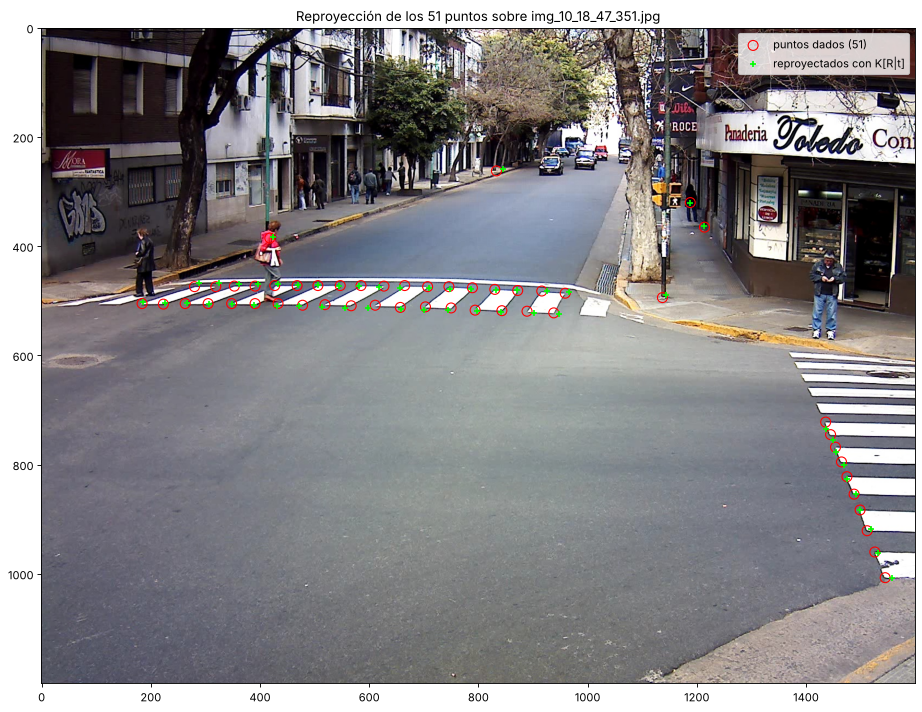

In [7]:
foto = mpimg.imread('recursos_entrega/salguero/img_10_18_47_351.jpg')
fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(foto)
ax.scatter(UV51[:, 0], UV51[:, 1], s=80, facecolors='none', edgecolors='r', label='puntos dados (51)')
ax.scatter(reproy[:, 0], reproy[:, 1], s=35, c='lime', marker='+', label='reproyectados con K[R|t]')
ax.set_title("Reproyección de los 51 puntos sobre img_10_18_47_351.jpg")
ax.legend()
plt.tight_layout()
plt.show()

b) La cámara queda a unos 3,7 m de altura, lo cual tiene sentido para una cámara sobre la calle. El error de reproyección es de unos 7 px (máximo ~14 px), parecido al de la propia homografía. Eso hace pensar que viene del ruido en los puntos o de la distorsión del lente (que el modelo pinhole no contempla) y no da un error en la pose. De todos modos, ese error limita la precisión de todo lo que sigue.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

**Qué vemos en**
- Los dos autos se acercan a la cámara ($Y$ baja) con velocidad bastante constante y casi sin irse de costado. La señora cruza por la senda peatonal ($X$ sube) caminando normal (alrededor de 1,4 m/s, unos 5 km/h).
- La velocidad entre capturas seguidas oscila bastante alrededor de la media, sobre todo al principio, cuando los autos están lejos: ahí un píxel son casi 1 m (ver el chequeo 1) y con $\Delta t\approx0{,}55$ s un error de un píxel cambia la velocidad en varios km/h. Por eso damos como resultado la velocidad media por recta ajustada, que usa todas las capturas, y mostramos las velocidades entre capturas para que se vea la dispersión.
- Los chequeos 2 y 3 dan valores parecidos a la media: la velocidad no cambia mucho según la mitad de la secuencia que miremos ni según cuál de las dos homografías usemos. Con los puntos que marcamos, el taxi va a unos 47 km/h, la camioneta a unos 54 km/h y la señora a unos 5 km/h.
- **Incertidumbre:** unos ±5 km/h para los autos (por el error de la homografía, de ≈7 px, y por la distancia) y menos de 1 km/h para la señora, que está cerca de la cámara.

**Limitaciones:** los puntos los marcamos a ojo sobre las capturas (error de unos 2 a 5 píxeles); puede haber distorsión del lente que el modelo pinhole no contempla; $H$ solo vale para el piso; asumimos que la cámara está fija; y los tiempos salen de los nombres de archivo, que tienen intervalos irregulares.